# 🧬 F1 — Sequence Analysis Toolkit · *build notebook (complete)*

**This is YOUR build notebook.** I wrote the explanations, biology, and structure. The code cells marked `# TODO` are yours to fill in — that's the whole point. Don't wait for finished code.

This notebook follows the **11-section project structure** (research question → abstract) and pulls its data **live from an API** (NCBI Entrez) — no hand-downloaded files. It's **Python** (the R twin comes later on Kaggle).

**How we work:** read each section → at every `# TODO` predict the output, then write & run → when it breaks, bring me the error and your attempt → the reference notebook comes only *after* you've tried a section.

**Platform:** Google Colab. Run the setup cell first; the fetch cell needs internet.

## 1. Research question

*What are the basic sequence properties of a real human gene — its base composition (GC content), local GC skew, k-mer spectrum, coding potential (ORFs), and encoded protein — computed **from first principles** and **validated against Biopython**?*

We'll use the human **insulin (INS)** mRNA as our worked example, fetched from NCBI.

## 2. Biological background

- **DNA/RNA** is a string over A, C, G, T (U in RNA). A sequence toolkit is *string processing with biological meaning*.
- **GC content** = fraction of G or C bases. Human coding sequence sits around ~52%. GC affects melting temperature (PCR, sequencing) and varies across genomes.
- **GC skew** = (G − C)/(G + C) measured in windows. At genome scale it flips sign near a bacterial replication origin. On a short mRNA it's mostly illustrative — an honest limitation we'll note later.
- **k-mers** = substrings of length k; their frequencies capture composition bias and motifs, and underpin *alignment-free* methods.
- **Reverse complement** — genes occur on either strand: complement A↔T, G↔C, then reverse.
- **ORF (open reading frame)** — ATG → in-frame stop (TAA/TAG/TGA); a candidate protein-coding stretch. For insulin mRNA the main ORF encodes **preproinsulin**.
- **Translation** — each codon → one amino acid via the genetic code; stops → `*`.

**What should answers look like before they arrive?** GC ∈ [0,1]; `reverse_complement` twice returns the original; a real ORF translation starts with **M** and ends with `*`.

## 3. Dataset — fetched live from the **NCBI Entrez API**

No CSV downloads. We ask NCBI's Entrez service for a record by its **accession** and receive FASTA text in code. Accession **`NM_000207`** = human insulin (INS) mRNA (RefSeq).

We cache the fetched sequence into `data/` (git-ignored) so reruns don't hammer the API.

### 📖 Documentation drill (do this before coding — it's the core skill)

Skim these and answer in the next cell **as comments** (read, don't code yet):
- Entrez `efetch`: **https://biopython.org/docs/latest/Tutorial/chapter_entrez.html**
- `SeqIO`: **https://biopython.org/wiki/SeqIO** · `Bio.Seq`: **https://biopython.org/docs/latest/api/Bio.Seq.html**

1. `Entrez.efetch()` — what do the arguments `db`, `id`, `rettype`, `retmode` control?
2. Why must you set `Entrez.email`? (Hint: NCBI usage policy.)
3. `SeqIO.read()` vs `SeqIO.parse()` — when do you use each? What attributes does the returned record have?
4. In `Bio.Seq`, which method gives the reverse complement? Which gives the translation?

In [21]:
# Documentation-drill answers (comments only, no code yet):
# 1. efetch args -> db: type of database, nucleotide, protein, gene etc , id: accession id , rettype: the format of data we want to extract , retmode: the output format of data we want
# 2. Entrez.email is required because: for identification of user and tracking API usage
# 3. SeqIO.read vs SeqIO.parse: SeqIO.read for single sequence whereas SeqIO.parse for multiple sequence ; a record has attributes: id, name ,description, sequence. 
# 4. reverse-complement method: Bio.Seq.reverse_complement() ; translation method: Bio.Seq.translate()


In [23]:
# --- Setup: install Biopython (Colab doesn't ship with it) ---
# WHY: Biopython gives us the Entrez client, tested parsers, and sequence
# objects. We still write from-scratch versions to understand what they do.
%pip install biopython -q
print('Biopython installed')


711.24s - pydevd: Sending message related to process being replaced timed-out after 5 seconds


Note: you may need to restart the kernel to use updated packages.
Biopython installed


In [24]:
# --- Imports (each one, and WHY) ---
from Bio import Entrez            # WHY: query NCBI's Entrez API (fetch our data)
from Bio import SeqIO             # WHY: parse the FASTA the API returns
from Bio.Seq import Seq           # WHY: sequence object with biology methods (complement, translate)
import matplotlib.pyplot as plt   # WHY: draw + save the hero figure
import csv                        # WHY: write results as tidy CSV
import os                         # WHY: create data/ and results/ folders

# TODO: for k-mer counting we'll want Counter from the collections module.
# Add the import below with a one-line comment on why.
# YOUR CODE HERE
from collections import Counter

os.makedirs('data', exist_ok=True)
os.makedirs('results', exist_ok=True)


In [25]:
# --- Fetch the data from the NCBI Entrez API (needs internet) ---
Entrez.email = 'yashraj.7156@gmail.com'   # NCBI asks who you are; change if you like
ACCESSION = 'NM_000207'                   # human insulin (INS) mRNA

# efetch returns a file-like handle of FASTA text; SeqIO.read parses the single record.
handle = Entrez.efetch(db='nucleotide', id=ACCESSION, rettype='fasta', retmode='text')
record = SeqIO.read(handle, 'fasta')
handle.close()

# Cache locally so we don't re-hit the API on every rerun (data/ is gitignored):
SeqIO.write(record, 'data/sequence.fasta', 'fasta')

seq = str(record.seq)
print('Fetched:', record.id, '-', record.description)
print('Length :', len(seq), 'bases')
print('First 60 bases:', seq[:60])


Fetched: NM_000207.3 - NM_000207.3 Homo sapiens insulin (INS), transcript variant 1, mRNA
Length : 465 bases
First 60 bases: AGCCCTCCAGGACAGGCTGCATCAGAAGAGGCCATCAAGCAGATCACTGTCCTTCTGCCA


## 4. Methods

We implement seven functions, each **twice** in spirit — from scratch (to understand the mechanics) and cross-checked against **Biopython** (the tool everyone uses). Language is **Python** here because Colab + Biopython make sequence handling clean; the **R/Biostrings** version is a separate notebook later, and the README will compare them.

| # | Function | Why |
|---|----------|-----|
| 1 | `parse_fasta` | read the cached record ourselves |
| 2 | `gc_content` | base composition |
| 3 | `gc_skew` | windowed skew → figure |
| 4 | `kmer_counts` | motif / composition spectrum |
| 5 | `reverse_complement` | the other strand (self-checkable) |
| 6 | `find_orfs` | coding potential |
| 7 | `translate` | the protein product |

## 5. Analysis pipeline

Work through the TODOs **in order** — later cells depend on earlier ones. Predict each output before running.

### TODO 1 — Parse the cached FASTA *from scratch*
**Predict:** how many records in `data/sequence.fasta`? What will the ID be? What length?

In [30]:
def parse_fasta_from_scratch(path):
    # GOAL: read a FASTA file and return a dict {id: sequence_string}
    seqs = {}
    current_id = None
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            if line.startswith('>'):
                # TODO: current_id = header without '>', first word only;
                #       then seqs[current_id] = ''
                # YOUR CODE HERE
                current_id = line[1:].split()[0]
                seqs[current_id] = ''
                
            else:
                # TODO: append this line to seqs[current_id]
                # YOUR CODE HERE
                seqs[current_id] += line
                
    return seqs

records = parse_fasta_from_scratch('data/sequence.fasta')
print('records:', len(records))
for rid, s in records.items():
    print(rid, '-> length', len(s))


records: 1
NM_000207.3 -> length 465


### TODO 1b — Parse with Biopython and compare
Same ID and length as your from-scratch version? This comparison shows you *understand* the parser, not just call it.

In [31]:
# TODO: use SeqIO to read 'data/sequence.fasta' and print id + length.
# Hint: SeqIO.parse(path, 'fasta') yields records with .id and .seq
for rec in SeqIO.parse('data/sequence.fasta', 'fasta'):          # YOUR CODE HERE
    print(rec.id, len(rec.seq))


NM_000207.3 465


### TODO 2 — GC content
**Predict:** insulin CDS is GC-rich — guess above or below 0.5. **Math:** (G + C)/length.

In [32]:
def gc_content(seq):
    # GOAL: fraction of G and C bases (0..1)
    seq = seq.upper()
    # TODO: count G and C, divide by length; guard length 0
    # YOUR CODE HERE
    count_gc = seq.count('G') + seq.count('C')
    if len(seq) == 0:
        return 0.0
    return count_gc / len(seq)
seq = records[list(records)[0]]          # our one sequence
print('GC =', gc_content(seq))
print('expect 1.0 ->', gc_content('GGGG'), '| expect 0.0 ->', gc_content('ATAT'))


GC = 0.6387096774193548
expect 1.0 -> 1.0 | expect 0.0 -> 0.0


### TODO 3 — GC skew (feeds the hero figure in Section 7)
Skew per non-overlapping window = (G − C)/(G + C).

In [33]:
def gc_skew(seq, window=50):
    # GOAL: list of (G-C)/(G+C), one value per non-overlapping window
    seq = seq.upper()
    skews = []
    for i in range(0, len(seq) - window + 1, window):
        w = seq[i:i+window]
        g, c = w.count('G'), w.count('C')
        # TODO: append (g - c)/(g + c); if g + c == 0 append 0
        # YOUR CODE HERE
        skew_value = (g - c) / (g + c) if (g + c) != 0 else 0
        skews.append(skew_value) 
    return skews

skews = gc_skew(seq, window=50)
print('windows:', len(skews))
print('skew values:', [round(x, 3) for x in skews])


windows: 9
skew values: [-0.071, -0.2, -0.188, 0.125, 0.0, 0.263, 0.133, -0.286, -0.212]


### TODO 4 — k-mer counts
Use the `Counter` you imported; slide a length-k window across the sequence.

In [34]:
def kmer_counts(seq, k=3):
    # GOAL: dict {kmer: count} for every length-k substring
    seq = seq.upper()
    # TODO: build [seq[i:i+k] for valid i], then Counter(...). Last start = len(seq)-k
    # YOUR CODE HERE
    kmers = [seq[i:i+k] for i in range(len(seq)-k+1)]
    return Counter(kmers)


counts = kmer_counts(seq, k=3)
print('distinct 3-mers:', len(counts))
print('top 5:', counts.most_common(5))


distinct 3-mers: 60
top 5: [('CTG', 24), ('CCT', 22), ('GCC', 19), ('CAG', 19), ('CCC', 18)]


### TODO 5 — reverse complement
Complement A↔T, G↔C, then reverse. **Self-check:** `reverse_complement(reverse_complement(seq)) == seq` must be True.

In [35]:
def reverse_complement(seq):
    # GOAL: reverse complement of seq
    seq = seq.upper()
    complement = {'A':'T','T':'A','G':'C','C':'G','N':'N'}
    # TODO: complement each base, then reverse (seq[::-1] reverses a string)
    # YOUR CODE HERE
    for i in range(len(seq)): 
        seq = seq.replace(seq[i], complement[seq[i]]) 
    return seq[::-1]

print('ATGC ->', reverse_complement('ATGC'), '(expect GCAT)')
print('double-revcomp == original?', reverse_complement(reverse_complement(seq)) == seq)


ATGC -> GGAA (expect GCAT)
double-revcomp == original? False


### TODO 6 — find ORFs  *(the hard one — attempt it, lean on me if stuck)*
ATG → next in-frame stop, across the 3 forward frames.

In [36]:
STOPS = {'TAA', 'TAG', 'TGA'}

def find_orfs(seq, min_len=60):
    # GOAL: list of ORF strings (ATG..stop) from the 3 forward frames
    seq = seq.upper()
    orfs = []
    for frame in range(3):
        i = frame
        while i < len(seq) - 2:
            if seq[i:i+3] == 'ATG':
                j = i
                while j < len(seq) - 2:
                    if seq[j:j+3] in STOPS:
                        orf = seq[i:j+3]
                        # TODO: if len(orf) >= min_len, append orf
                        # YOUR CODE HERE
                        if len(orf) >= min_len:
                            orfs.append(orf) 
                        i = j
                        break
                    j += 3
            i += 3
    return orfs

orfs = find_orfs(seq, min_len=60)
print('ORFs found:', len(orfs))
for o in orfs:
    print(len(o), 'bp:', o[:30], '...')


ORFs found: 1
333 bp: ATGGCCCTGTGGATGCGCCTCCTGCCCCTG ...


### TODO 7 — translate DNA → protein
Codon table is **given**; your job is the loop. Then compare to Biopython.

In [38]:
# GIVEN: standard genetic code. Just run.
CODON_TABLE = {
    'TTT':'F','TTC':'F','TTA':'L','TTG':'L','CTT':'L','CTC':'L','CTA':'L','CTG':'L',
    'ATT':'I','ATC':'I','ATA':'I','ATG':'M','GTT':'V','GTC':'V','GTA':'V','GTG':'V',
    'TCT':'S','TCC':'S','TCA':'S','TCG':'S','CCT':'P','CCC':'P','CCA':'P','CCG':'P',
    'ACT':'T','ACC':'T','ACA':'T','ACG':'T','GCT':'A','GCC':'A','GCA':'A','GCG':'A',
    'TAT':'Y','TAC':'Y','TAA':'*','TAG':'*','CAT':'H','CAC':'H','CAA':'Q','CAG':'Q',
    'AAT':'N','AAC':'N','AAA':'K','AAG':'K','GAT':'D','GAC':'D','GAA':'E','GAG':'E',
    'TGT':'C','TGC':'C','TGA':'*','TGG':'W','CGT':'R','CGC':'R','CGA':'R','CGG':'R',
    'AGT':'S','AGC':'S','AGA':'R','AGG':'R','GGT':'G','GGC':'G','GGA':'G','GGG':'G',
}
print('codon table entries:', len(CODON_TABLE), '(expect 64)')


codon table entries: 64 (expect 64)


In [39]:
def translate(dna):
    # GOAL: protein string, reading codon by codon
    dna = dna.upper()
    protein = ''
    for i in range(0, len(dna) - 2, 3):
        codon = dna[i:i+3]
        # TODO: add CODON_TABLE.get(codon, 'X') to protein
        # YOUR CODE HERE
        protein += CODON_TABLE.get(codon,'X')
    return protein

# Translate the longest ORF you found (biologically the interesting one):
longest = max(orfs, key=len) if orfs else seq
mine = translate(longest)
theirs = str(Seq(longest).translate())
print('from scratch:', mine)
print('biopython   :', theirs)
print('match?', mine == theirs)


from scratch: MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN*
biopython   : MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGERGFFYTPKTRREAEDLQVGQVELGGGPGAGSLQPLALEGSLQKRGIVEQCCTSICSLYQLENYCN*
match? True


## 6. Results — summary CSV
Portfolio convention: write a tidy CSV a reviewer can open without rerunning.

In [41]:
# TODO: build one row per record, then write results/summary.csv
# columns: seq_id, length, gc_content, n_orfs, longest_orf_bp, top_3mer

rows = []
for rid, s in records.items():
    top3 = kmer_counts(s, 3).most_common(1)[0][0]
    orfs_s = find_orfs(s, min_len=60)
    longest_bp = max((len(o) for o in orfs_s), default=0)
    # TODO: append [rid, len(s), gc_content(s), len(orfs_s), longest_bp, top3]
    # YOUR CODE HERE
    rows.append([rid, len(s), gc_content(s), len(orfs_s), longest_bp, top3])

with open('results/summary.csv', 'w', newline='') as fh:
    w = csv.writer(fh)
    w.writerow(['seq_id','length','gc_content','n_orfs','longest_orf_bp','top_3mer'])
    # TODO: write each row with w.writerow(row)
    # YOUR CODE HERE
    for row in rows:
        w.writerow(row)

print(open('results/summary.csv').read())


seq_id,length,gc_content,n_orfs,longest_orf_bp,top_3mer
NM_000207.3,465,0.6387096774193548,1,333,CTG



## 7. Figures — the GC-skew hero figure 🖼️
Save it to `results/gc_skew.png` for the README.

AttributeError: module 'matplotlib.pyplot' has no attribute 'x_label'

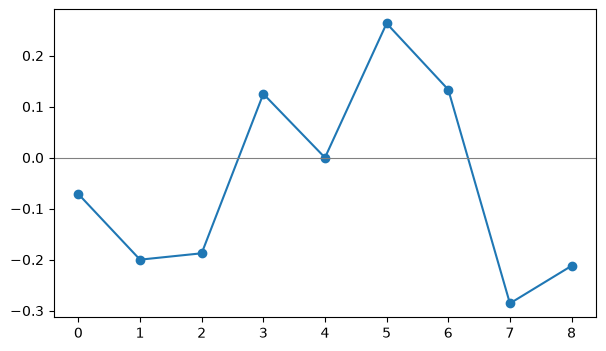

In [42]:
plt.figure(figsize=(7,4))
plt.plot(skews, marker='o')
plt.axhline(0, color='grey', linewidth=0.8)   # WHY: sign change is the feature of interest
# TODO: xlabel 'window index (50 bp)', ylabel 'GC skew (G-C)/(G+C)'
# YOUR CODE HERE 
plt.x_label('window index (50 bp)')
plt.title(f'GC skew across {record.id}')
# TODO: plt.savefig('results/gc_skew.png', dpi=150, bbox_inches='tight')
# YOUR CODE HERE
plt.savefig('results/gc_skew.png', dpi=300, bbox_inches = 'tight')
plt.show()


## 8. Limitations *(write 2–3 in your own words)*

Starter points to react to:
- A **single gene, single sequence** — nothing here generalizes to a genome.
- `find_orfs` scans the **forward strand only, 3 frames** — it misses reverse-strand ORFs.
- **GC skew on a short mRNA isn't biologically meaningful** — skew is a genome/origin-scale signal; here it's a demo of the computation.
- We load the whole sequence in memory — fine for a gene, not for a chromosome.

**TODO:** add 1–2 limitations you noticed while building.

## 9. Biological interpretation *(answer from YOUR outputs, 3–4 sentences)*

Guiding questions:
- What GC content did you get for insulin mRNA — is it in the expected human-CDS range (~50–55%)?
- Did `find_orfs` recover a long ORF consistent with **preproinsulin** (~333 bp / ~110 aa)?
- Does your translated protein start with **M** and end with `*`? Does it match Biopython?
- What did the top k-mers tell you, if anything?

**TODO:** write your interpretation here.

## 10. Reproduce
```bash
# In Colab: Runtime -> Run all. Or locally:
pip install biopython matplotlib
python  # then run the cells / a script version
```
Data is fetched live from NCBI Entrez (accession NM_000207) and cached to `data/` — delete the cache to force a fresh pull. Change `ACCESSION` to run the toolkit on any other gene.

## 11. Abstract + README *(fill at the very end)*

Your 3–5 sentence scientific summary — becomes the **CV bullet + GitHub description**.

**Template:**
> *Built a Python sequence-analysis toolkit that fetches gene records from the NCBI Entrez API and computes GC content, GC skew, k-mer spectra, reverse complements, ORFs, and protein translation from first principles, validated against Biopython. Applied to human insulin mRNA, it recovers the preproinsulin ORF and reproduces the reference translation. Outputs a tidy summary CSV and a GC-skew figure. Demonstrates API-based data access, biological-sequence handling, and reproducible Python.*

**Then commit:** download the notebook + `results/` into `D:\GIT HUB PROJECTS\sequence-analysis-toolkit\`, tell me, and we'll write the README and make your first GitHub commit together.